# Different Phases
Let's define different phases in our experiment
- Phase 1: Classify IoT vs non-IoT
- Phase 2: Two directions
    - Only classify device type
    - Classify device type and vendor
- Phase 3: Classify events

In [48]:
import os 
import sys
import pandas as pd 
from typing import Dict, List
from pathlib import Path
from scipy.stats import skew, kurtosis
from package import training_and_evaluation
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [3]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:.6f}".format)

# Dataset 1 - Identify IoT devices and events dataset
## Extract raw data and device mapping list

In [5]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [6]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Insteon'},
 'e8:ab:fa:19:de:4f': {'device_name': 'Insteon Camera',
  'ip_address': nan,
  'is_io

In [7]:
df = pd.read_csv(csv_files_1[0])

/var/folders/rv/241jb89d0rn0z37gwxcvxhxc0000gn/T/ipykernel_71642/1465641618.py:1: DtypeWarning: Columns (0: eth.trailer, 1: igmp.type) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_files_1[0])


In [8]:
df.head(10)

,frame.number,frame.time_epoch,frame.time_relative,frame.time_delta,frame.cap_len,frame.len,frame.interface_id,frame.encap_type,frame.protocols,eth.src,eth.dst,eth.src.oui,eth.dst.oui,eth.type,eth.len,eth.padding,eth.trailer,eth.fcs,eth.fcs.status,vlan.id,vlan.priority,vlan.etype,arp.opcode,arp.src.hw_mac,arp.src.proto_ipv4,arp.dst.hw_mac,arp.dst.proto_ipv4,ip.version,ip.hdr_len,ip.dsfield,ip.len,ip.id,ip.flags,ip.flags.df,ip.flags.mf,ip.frag_offset,ip.ttl,ip.proto,ip.checksum,ip.checksum.status,ip.src,ip.dst,ipv6.version,ipv6.tclass,ipv6.flow,ipv6.plen,ipv6.nxt,ipv6.hlim,ipv6.src,ipv6.dst,icmp.type,icmp.code,icmp.checksum,icmpv6.type,icmpv6.code,igmp.type,igmp.version
0,1,1474552802.257569,0.000000,NaN,70,70,0,1,eth:ethertype:ip:tcp:data,18:b7:9e:02:20:44,14:cc:20:51:33:ea,1619870,1362976,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,56.000000,0x8492,0x02,True,False,0.000000,64.000000,6.000000,0x9f55,2.000000,192.168.1.120,46.105.38.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1474552802.257692,0.000123,0.000123,66,66,0,1,eth:ethertype:ip:tcp,18:b7:9e:02:20:44,14:cc:20:51:33:ea,1619870,1362976,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,52.000000,0x8493,0x02,True,False,0.000000,64.000000,6.000000,0x9f58,2.000000,192.168.1.120,46.105.38.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1474552802.323085,0.065516,0.065393,66,66,0,1,eth:ethertype:ip:tcp,14:cc:20:51:33:ea,30:8c:fb:2f:e4:b2,1362976,3181819,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,52.000000,0xd580,0x02,True,False,0.000000,224.000000,6.000000,0xdd39,2.000000,52.87.241.159,192.168.1.106,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1474552802.383174,0.125605,0.060089,60,60,0,1,eth:ethertype:ip:tcp,d0:52:a8:00:67:5e,14:cc:20:51:33:ea,13652648,1362976,0x0800,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,41.000000,0x69b0,0x00,False,False,0.000000,100.000000,6.000000,0xce37,2.000000,192.168.1.196,52.1.40.122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,1474552802.396326,0.138757,0.013152,98,98,0,1,eth:ethertype:ip:icmp:data,14:cc:20:51:33:ea,70:ee:50:18:34:43,1362976,7401040,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,84.000000,0x5956,0x00,False,False,0.000000,45.000000,1.000000,0xe671,2.000000,195.154.199.173,192.168.1.241,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0xb990,NaN,NaN,NaN,NaN
5,6,1474552802.447911,0.190342,0.051585,88,88,0,1,eth:ethertype:ip:udp:dns,70:ee:50:18:34:43,14:cc:20:51:33:ea,7401040,1362976,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,74.000000,0x6677,0x02,True,False,0.000000,64.000000,17.000000,0x4fe9,2.000000,192.168.1.241,192.168.1.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,1474552802.555796,0.298227,0.107885,68,68,0,1,eth:ethertype:ip:tcp:data,14:cc:20:51:33:ea,18:b7:9e:02:20:44,1362976,1619870,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,54.000000,0x6d75,0x02,True,False,0.000000,48.000000,6.000000,0xc674,2.000000,46.105.38.79,192.168.1.120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,1474552802.587523,0.329954,0.031727,54,54,0,1,eth:ethertype:ip:tcp,14:cc:20:51:33:ea,d0:52:a8:00:67:5e,1362976,13652648,0x0800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,20.000000,0x00,40.000000,0xc44c,0x02,True,False,0.000000,32.000000,6.000000,0x779c,2.000000,52.1.40.122,192.168.1.196,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,1474552802.634732,0.377163,0.047209,42,42,0,1,eth:ethertype:arp,ec:1a:59:79:f4:89,14:cc:20:51:33:ea,15473241,1362976,0x0806,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,ec:1a:59:79:f4:89,192.168.1.223,00:00:00:00:00:00,192.168.1.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

- There are multiple empty entries for IP address, thus I will be using MAC address to label the traffic
## Feature Set 1 - Statistical Distribution Features

In [ ]:
FIXED_WINDOW = 10 # 10 seconds

In [ ]:
def combine_and_extract_without_cdf(file_paths: Iterable[str]) -> pd.DataFrame:
    columns = ["frame.time_epoch", "frame.len", "eth.src", "eth.dst"]
    all_features = []

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category",
            },
        )

        start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - start) // FIXED_WINDOW
        ).astype("int32")

        grouped = df.groupby(
            ["window", "eth.src"],
            sort=False,
            observed=True,
        )["frame.len"]

        basic_features = grouped.agg(
            packet_count="size",
            total_bytes="sum",
            frame_length_mean="mean",
        )

        basic_features["frame_length_std"] = grouped.std(ddof=0)

        quantiles = (
            grouped
            .quantile([0.25, 0.50, 0.75, 0.95])
            .unstack()
            .rename(
                columns={
                    0.25: "frame_length_q25",
                    0.50: "frame_length_median",
                    0.75: "frame_length_q75",
                    0.95: "frame_length_q95",
                }
            )
        )

        features = (
            basic_features
            .join(quantiles)
            .reset_index()
        )

        all_features.append(features)

    return pd.concat(all_features, ignore_index=True)

In [11]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [ ]:
# all_data = combine_and_extract_without_cdf(csv_files_1)

In [13]:
# labeled_data = label_features(all_data, device_dict_1)

In [14]:
# labeled_data.head(10)

### Phase 1 Experiment

In [15]:
# training_features = ["packet_count", "total_bytes", "frame_length_mean", "frame_length_std", "frame_length_q25", "frame_length_median", "frame_length_q75", "frame_length_q95"]
# label = "is_iot_device"
# X, y = labeled_data[training_features], labeled_data[label]

In [16]:
# X.isna().sum()

In [17]:
# y.value_counts()

In [18]:
# first_experiment_results = training_and_evaluation(X, y)
# first_experiment_results.to_csv("first_experiment_results_300_window_second.csv", index=False)


# phase_1_result = pd.read_csv("first_experiment_results_300_window_second.csv")
# phase_1_result

In [19]:
# first_experiment_results

### Phase 2 Experiment - Identify Device Types

In [ ]:
# training_features = ["packet_count", "total_bytes", "frame_length_mean", "frame_length_std", "frame_length_q25", "frame_length_median", "frame_length_q75", "frame_length_q95"]
# label = "device_type"
# filtered_data = labeled_data[labeled_data["is_iot_device"] == 1]
# X, y = filtered_data[training_features], filtered_data[label]

In [21]:
# X.isna().sum()

In [22]:
# y.value_counts()

In [23]:
# second_experiment_results = training_and_evaluation(X, y)
# second_experiment_results.to_csv("second_experiment_results_300_window_second.csv", index=False)

In [24]:
# second_experiment_results

In [75]:
# second_experiment_results = pd.read_csv("second_experiment_results_300_window_second.csv")
# second_experiment_results

## Feature Set 2 - Include the CDF notation

In [66]:
def combine_and_extract_with_cdf(file_paths: Iterable[str]) -> pd.DataFrame:
    CDF_THRESHOLDS = (64, 128, 256, 512, 1024)
    columns = ["frame.time_epoch", "frame.len", "eth.src", "eth.dst"]
    group_columns = ["window", "eth.src"]

    all_features = []

    for file_id, file_path in enumerate(file_paths):
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category",
            },
        )

        if df.empty:
            continue

        start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - start) // FIXED_WINDOW
        ).astype("int32")

        # cdf_128 = mean(frame.len <= 128)
        #         = proportion of packets whose length is <= 128 bytes
        cdf_columns = []

        for threshold in CDF_THRESHOLDS:
            column = f"frame_length_cdf_{threshold}"
            df[column] = df["frame.len"].le(threshold)
            cdf_columns.append(column)

        # Create the GroupBy object once and reuse it.
        grouped_df = df.groupby(
            group_columns,
            sort=False,
            observed=True,
        )

        grouped_lengths = grouped_df["frame.len"]

        basic_features = grouped_lengths.agg(
            packet_count="size",
            total_bytes="sum",
            frame_length_mean="mean",
            frame_length_min="min",
            frame_length_max="max",
        )

        # Population standard deviation.
        basic_features["frame_length_std"] = grouped_lengths.std(ddof=0)

        quantiles = (
            grouped_lengths
            .quantile([0.25, 0.50, 0.75, 0.95])
            .unstack()
            .rename(
                columns={
                    0.25: "frame_length_q25",
                    0.50: "frame_length_median",
                    0.75: "frame_length_q75",
                    0.95: "frame_length_q95",
                }
            )
        )

        # Boolean mean gives the fraction of True values.
        cdf_features = grouped_df[cdf_columns].mean()

        features = basic_features.join(
            [quantiles, cdf_features]
        )

        # Additional distribution-shape features
        features["frame_length_iqr"] = (
            features["frame_length_q75"]
            - features["frame_length_q25"]
        )

        features["frame_length_upper_tail"] = (
            features["frame_length_q95"]
            - features["frame_length_q75"]
        )

        features = features.reset_index()


        all_features.append(features)

    if not all_features:
        return pd.DataFrame()

    return pd.concat(all_features, ignore_index=True)

In [67]:
computed_features_set_2 = combine_and_extract_with_cdf(csv_files_1)

In [71]:
computed_features_set_2.columns

Index(['window', 'eth.src', 'packet_count', 'total_bytes', 'frame_length_mean',
       'frame_length_min', 'frame_length_max', 'frame_length_std',
       'frame_length_q25', 'frame_length_median', 'frame_length_q75',
       'frame_length_q95', 'frame_length_cdf_64', 'frame_length_cdf_128',
       'frame_length_cdf_256', 'frame_length_cdf_512', 'frame_length_cdf_1024',
       'frame_length_iqr', 'frame_length_upper_tail', 'is_iot_device',
       'device_type', 'vendor'],
      dtype='str')

In [69]:
features_set_2_with_labels = label_features(computed_features_set_2, device_dict_1)

In [72]:
training_features = ['packet_count', 'total_bytes', 'frame_length_mean',
       'frame_length_min', 'frame_length_max', 'frame_length_std',
       'frame_length_q25', 'frame_length_median', 'frame_length_q75',
       'frame_length_q95', 'frame_length_cdf_64', 'frame_length_cdf_128',
       'frame_length_cdf_256', 'frame_length_cdf_512', 'frame_length_cdf_1024',
       'frame_length_iqr', 'frame_length_upper_tail']
label = "device_type"
filtered_data_2 = features_set_2_with_labels[features_set_2_with_labels["is_iot_device"] == 1]
X, y = filtered_data_2[training_features], filtered_data_2[label]

In [73]:
X.isna().sum()

packet_count               0
total_bytes                0
frame_length_mean          0
frame_length_min           0
frame_length_max           0
frame_length_std           0
frame_length_q25           0
frame_length_median        0
frame_length_q75           0
frame_length_q95           0
frame_length_cdf_64        0
frame_length_cdf_128       0
frame_length_cdf_256       0
frame_length_cdf_512       0
frame_length_cdf_1024      0
frame_length_iqr           0
frame_length_upper_tail    0
dtype: int64

In [74]:
y.value_counts()

device_type
camera                    525396
smart speaker             182837
baby monitor              125848
sleep sensor               97819
motion sensor              73976
smart switch               72188
printer                    61079
smart bulb                 36860
smart plug                 29150
weather station            28486
photo frame                12267
smart scale                  138
smoke alarm                   82
blood pressure monitor         7
Name: count, dtype: int64

In [76]:
third_experiment_results = training_and_evaluation(X, y)
third_experiment_results.to_csv("third_experiment_results_10_window_third.csv", index=False)

Training and evaluating with:
Features: ['packet_count', 'total_bytes', 'frame_length_mean', 'frame_length_min', 'frame_length_max', 'frame_length_std', 'frame_length_q25', 'frame_length_median', 'frame_length_q75', 'frame_length_q95', 'frame_length_cdf_64', 'frame_length_cdf_128', 'frame_length_cdf_256', 'frame_length_cdf_512', 'frame_length_cdf_1024', 'frame_length_iqr', 'frame_length_upper_tail']
Label: ['baby monitor' 'blood pressure monitor' 'camera' 'motion sensor'
 'photo frame' 'printer' 'sleep sensor' 'smart bulb' 'smart plug'
 'smart scale' 'smart speaker' 'smart switch' 'smoke alarm'
 'weather station']
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sam

In [77]:
third_experiment_results

,accuracy,precision_class_baby monitor,recall_class_baby monitor,f1_class_baby monitor,precision_class_blood pressure monitor,recall_class_blood pressure monitor,f1_class_blood pressure monitor,precision_class_camera,recall_class_camera,f1_class_camera,precision_class_motion sensor,recall_class_motion sensor,f1_class_motion sensor,precision_class_photo frame,recall_class_photo frame,f1_class_photo frame,precision_class_printer,recall_class_printer,f1_class_printer,precision_class_sleep sensor,recall_class_sleep sensor,f1_class_sleep sensor,precision_class_smart bulb,recall_class_smart bulb,f1_class_smart bulb,precision_class_smart plug,recall_class_smart plug,f1_class_smart plug,precision_class_smart scale,recall_class_smart scale,f1_class_smart scale,precision_class_smart speaker,recall_class_smart speaker,f1_class_smart speaker,precision_class_smart switch,recall_class_smart switch,f1_class_smart switch,precision_class_smoke alarm,recall_class_smoke alarm,f1_class_smoke alarm,precision_class_weather station,recall_class_weather station,f1_class_weather station,model,sample_method,iteration,labels
0,0.834396,0.990573,0.972705,0.981557,1.000000,1.000000,1.000000,0.999853,0.841110,0.913637,0.792746,0.227509,0.353553,0.330899,0.793806,0.467090,0.681674,0.863867,0.762032,0.999634,0.977459,0.988422,0.302958,0.983587,0.463234,0.640947,0.785077,0.705728,0.964286,1.000000,0.981818,0.946076,0.890478,0.917436,0.512233,0.690262,0.588069,1.000000,1.000000,1.000000,0.893507,1.000000,0.943759,DecisionTree,RandomUnderSampler,0,"[baby monitor, blood pressure monitor, camera,..."
1,0.831451,0.981451,0.973302,0.977359,1.000000,1.000000,1.000000,0.999874,0.829947,0.907020,0.788136,0.251436,0.381245,0.302613,0.807175,0.440196,0.599759,0.857073,0.705692,0.999728,0.941014,0.969483,0.332871,0.943299,0.492092,0.679531,0.915094,0.779914,1.000000,1.000000,1.000000,0.936013,0.906065,0.920796,0.510768,0.678465,0.582793,1.000000,0.941176,0.969697,0.865934,0.995261,0.926104,DecisionTree,RandomUnderSampler,1,"[baby monitor, blood pressure monitor, camera,..."
2,0.823775,0.975995,0.970799,0.973390,1.000000,1.000000,1.000000,0.999736,0.829501,0.906697,0.779127,0.234133,0.360064,0.280528,0.806360,0.416246,0.569360,0.859447,0.684956,0.999337,0.847066,0.916923,0.313154,0.929734,0.468505,0.676297,0.923499,0.780799,1.000000,1.000000,1.000000,0.964698,0.912462,0.937853,0.514171,0.684838,0.587358,1.000000,0.937500,0.967742,0.835277,0.993330,0.907473,DecisionTree,RandomUnderSampler,2,"[baby monitor, blood pressure monitor, camera,..."
3,0.826234,0.972552,0.968534,0.970539,1.000000,1.000000,1.000000,0.999610,0.854690,0.921487,0.773817,0.246502,0.373898,0.329511,0.796576,0.466182,0.521845,0.875082,0.653803,0.999310,0.814292,0.897364,0.331173,0.935567,0.489184,0.697604,0.908919,0.789364,1.000000,0.964286,0.981818,0.946540,0.896245,0.920706,0.508340,0.612135,0.555430,1.000000,0.875000,0.933333,0.835918,0.993505,0.907924,DecisionTree,RandomUnderSampler,3,"[baby monitor, blood pressure monitor, camera,..."
4,0.810887,0.967713,0.976479,0.972076,0.000000,0.000000,0.000000,0.998959,0.849152,0.917984,0.739294,0.225196,0.345231,0.350769,0.836186,0.494220,0.494847,0.880475,0.633597,0.997133,0.711102,0.830171,0.301197,0.938280,0.456011,0.692517,0.828645,0.754490,0.793103,0.821429,0.807018,0.944758,0.879728,0.911084,0.491582,0.598629,0.539850,0.700000,0.875000,0.777778,0.824587,0.990170,0.899825,DecisionTree,RandomUnderSampler,4,"[baby monitor, blood pressure monitor, camera,..."
5,0.834396,0.990572,0.972665,0.981537,1.000000,1.000000,1.000000,0.999842,0.841091,0.913621,0.793673,0.227239,0.353318,0.331012,0.794214,0.467274,0.681630,0.863867,0.762004,0.999634,0.977459,0.988422,0.302945,0.983587,0.463219,0.640857,0.785077,0.705674,0.964286,1.000000,0.981818,0.945963,0.890423,0.917353,0.512302,0.690816,0.588315,1.000000,1.000000,1.000000,0.894489,1.000000,0.944306,RandomForest,RandomUnderSampler,0,"[baby monitor, blood pressure monitor, camera,..."
6,0.831459,0.981490,0.973302,0.977

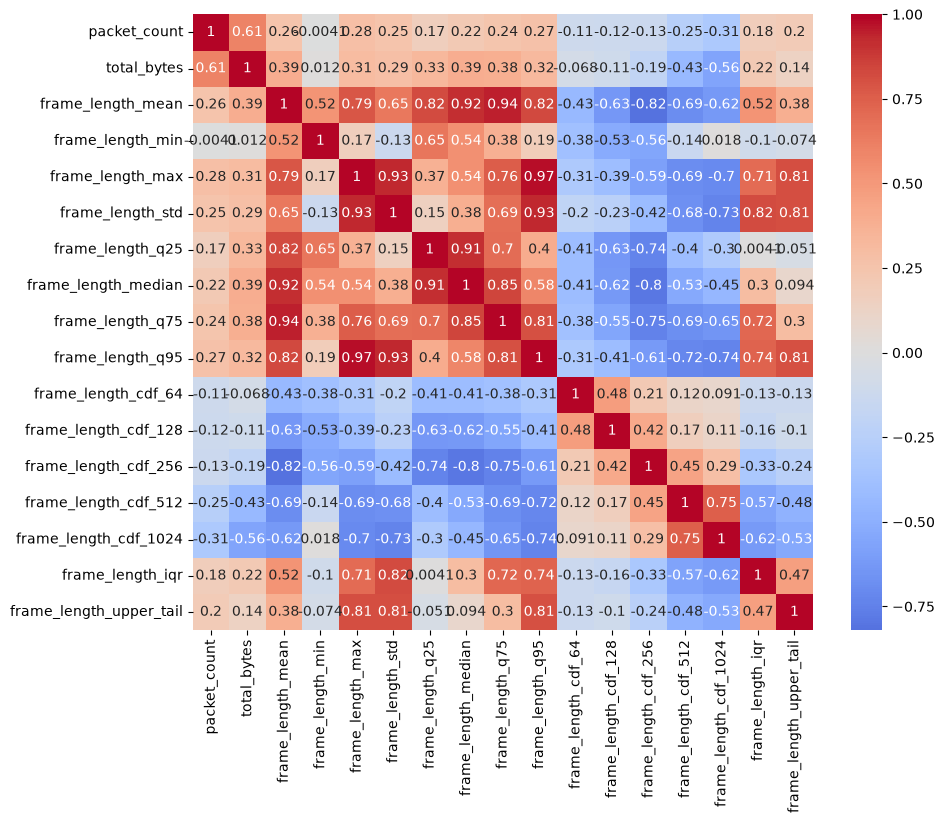

In [79]:
corr = X.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.show()

## Observing the pattern

In [25]:
def extract_raw_data(file_paths: Iterable[str]) -> pd.DataFrame:
    columns = ["frame.time_epoch", "frame.len", "eth.src", "eth.dst"]
    all_features = []

    for file_path in file_paths:
        file_name = os.path.basename(file_path)
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category",
            },
        )
        df["dataset"] = file_name
        all_features.append(df)
    
    return pd.concat(all_features, ignore_index=True)

    

In [26]:
all_raw_data = extract_raw_data(csv_files_1)

In [27]:
all_raw_data["eth.src"].value_counts()

eth.src
14:cc:20:51:33:ea    12324189
74:2f:68:81:69:42     2436873
30:8c:fb:2f:e4:b2     2134133
00:16:6c:ab:6b:88      966018
ec:1a:59:83:28:11      749663
ac:bc:32:d4:6f:2f      743415
44:65:0d:56:cc:d3      705719
ec:1a:59:79:f4:89      612025
00:62:6e:51:27:2e      500653
08:21:ef:3b:fc:e3      453071
70:ee:50:18:34:43      369953
00:24:e4:11:18:a8      350718
d0:52:a8:00:67:5e      290755
00:24:e4:20:28:c6      239721
f4:f2:6d:93:51:f1      198066
70:5a:0f:e4:9b:c0      166419
70:ee:50:03:b8:ac      130751
18:b7:9e:02:20:44      111573
d0:73:d5:01:83:08       88028
30:8c:fb:b6:ea:45       76988
e0:76:d0:33:bb:85       42374
b4:ce:f6:a7:a3:c2       40486
74:c6:3b:29:d7:1d       35300
50:c7:bf:00:56:39       25087
f4:5c:89:93:cc:85        9633
40:f3:08:ff:1e:da        5879
00:24:e4:1b:6f:96        2985
18:b4:30:25:be:e4        2317
00:24:e4:10:ee:4c        1234
d0:a6:37:df:a1:e1        1182
e8:ab:fa:19:de:4f         364
74:6a:89:00:2e:25         131
d2:13:91:23:2a:58          13
8a

In [29]:
device_dict_1

{'44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Insteon'},
 'e8:ab:fa:19:de:4f': {'device_name': 'Insteon Camera',
  'ip_address': nan,
  'is_io

In [30]:
all_raw_data.head(10)

,frame.time_epoch,frame.len,eth.src,eth.dst,dataset
0,1474552802.257569,70,18:b7:9e:02:20:44,14:cc:20:51:33:ea,16-09-23.csv
1,1474552802.257692,66,18:b7:9e:02:20:44,14:cc:20:51:33:ea,16-09-23.csv
2,1474552802.323085,66,14:cc:20:51:33:ea,30:8c:fb:2f:e4:b2,16-09-23.csv
3,1474552802.383174,60,d0:52:a8:00:67:5e,14:cc:20:51:33:ea,16-09-23.csv
4,1474552802.396326,98,14:cc:20:51:33:ea,70:ee:50:18:34:43,16-09-23.csv
5,1474552802.447911,88,70:ee:50:18:34:43,14:cc:20:51:33:ea,16-09-23.csv
6,1474552802.555796,68,14:cc:20:51:33:ea,18:b7:9e:02:20:44,16-09-23.csv
7,1474552802.587523,54,14:cc:20:51:33:ea,d0:52:a8:00:67:5e,16-09-23.csv
8,1474552802.634732,42,ec:1a:59:79:f4:89,14:cc:20:51:33:ea,16-09-23.csv
9,1474552802.634774,42,14:cc:20:51:33:ea,ec:1a:59:79:f4:89,16-09-23.csv


In [ ]:
# MAX_POINTS = 50000

# for mac, device_df in all_raw_data.groupby("eth.src"):
#     # Use device name if known; otherwise use the MAC address
#     if mac in device_dict_1:
#         title = f"{device_dict_1[mac]['device_name']} ({mac})"
#     else:
#         title = mac

#     for dataset, df_day in device_df.groupby("dataset"):
#         df_day = df_day.sort_values("frame.time_epoch").copy()

#         # Optional: subsample large traces
#         if len(df_day) > MAX_POINTS:
#             df_day = (
#                 df_day.sample(MAX_POINTS, random_state=42)
#                       .sort_values("frame.time_epoch")
#             )

#         # Normalize time
#         t = df_day["frame.time_epoch"] - df_day["frame.time_epoch"].min()

#         plt.figure(figsize=(15, 5))

#         plt.scatter(
#             t,
#             df_day["frame.len"],
#             s=1,
#             alpha=0.15,
#             rasterized=True,
#         )

#         plt.title(f"{title} - {dataset}")
#         plt.xlabel("Time since first packet (seconds)")
#         plt.ylabel("Frame Length (Bytes)")
#         plt.grid(alpha=0.3)

#         plt.tight_layout()
#         plt.show()

In [42]:
phase_1_computed_features = combine_and_extract(csv_files_1[0:1])

In [43]:
phase_1_computed_features.head(10)

,window,eth.src,packet_count,total_bytes,frame_length_mean,frame_length_std,frame_length_q25,frame_length_median,frame_length_q75,frame_length_q95
0,0,18:b7:9e:02:20:44,4,244,61.000000,11.090537,60.000000,66.000000,67.000000,69.400000
1,0,14:cc:20:51:33:ea,27,2052,76.000000,39.979624,60.000000,66.000000,77.000000,123.000000
2,0,d0:52:a8:00:67:5e,3,259,86.333333,37.240957,60.000000,60.000000,99.500000,131.100000
3,0,70:ee:50:18:34:43,3,284,94.666667,4.714045,93.000000,98.000000,98.000000,98.000000
4,0,ec:1a:59:79:f4:89,86,23991,278.965116,415.225085,66.000000,74.000000,300.750000,1514.000000
5,0,30:8c:fb:2f:e4:b2,9,1404,156.000000,0.000000,156.000000,156.000000,156.000000,156.000000
6,0,00:24:e4:11:18:a8,2,132,66.000000,0.000000,66.000000,66.000000,66.000000,66.000000
7,0,08:21:ef:3b:fc:e3,2,108,54.000000,12.000000,48.000000,54.000000,60.000000,64.800000
8,0,f4:f2:6d:93:51:f1,3,256,85.333333,53.024104,48.000000,54.000000,107.000000,149.400000
9,0,44:65:0d:56:cc:d3,2,392,196.000000,5.000000,193.500000,196.000000,198.500000,200.500000


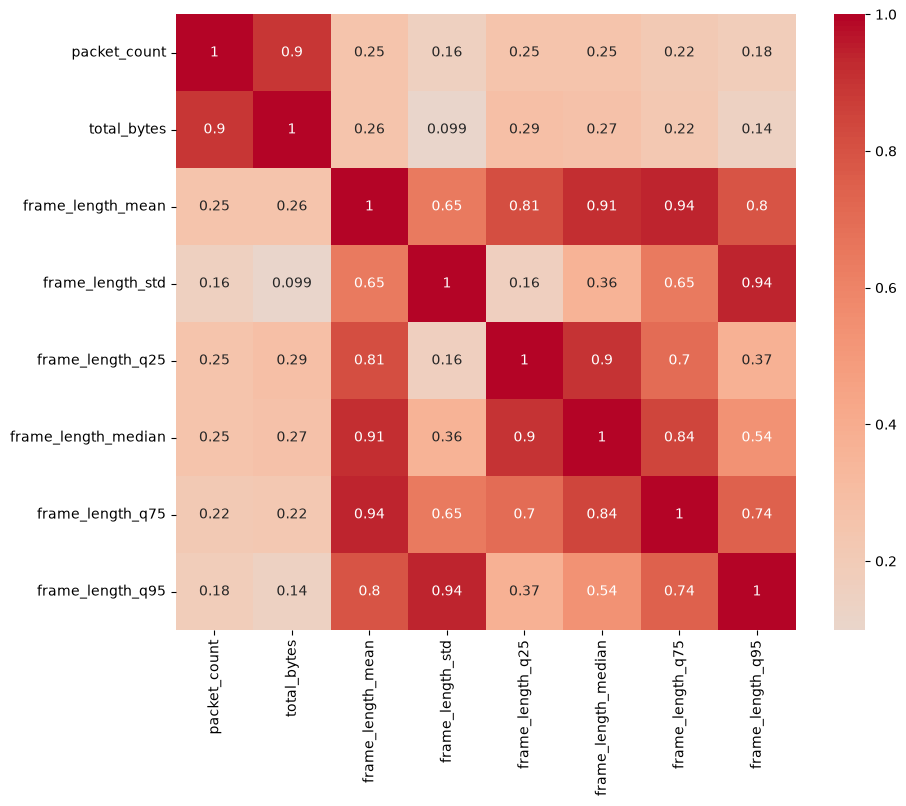

In [49]:
corr = phase_1_computed_features.drop(columns=["window"]).corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.show()

array([[<Axes: title={'center': 'packet_count'}>,
        <Axes: title={'center': 'total_bytes'}>,
        <Axes: title={'center': 'frame_length_mean'}>],
       [<Axes: title={'center': 'frame_length_std'}>,
        <Axes: title={'center': 'frame_length_q25'}>,
        <Axes: title={'center': 'frame_length_median'}>],
       [<Axes: title={'center': 'frame_length_q75'}>,
        <Axes: title={'center': 'frame_length_q95'}>, <Axes: >]],
      dtype=object)

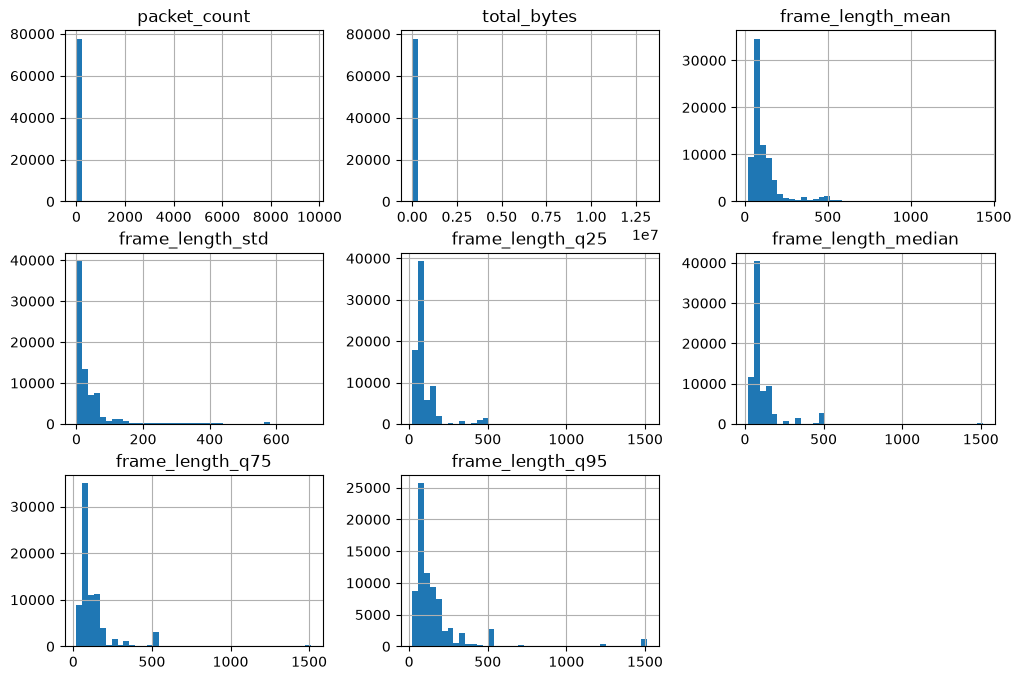

In [46]:
numeric = [
    "packet_count",
    "total_bytes",
    "frame_length_mean",
    "frame_length_std",
    "frame_length_q25",
    "frame_length_median",
    "frame_length_q75",
    "frame_length_q95",
]

phase_1_computed_features[numeric].hist(
    figsize=(12,8),
    bins=40
)

Text(0.5, 1.0, '18:b4:30:25:be:e4')

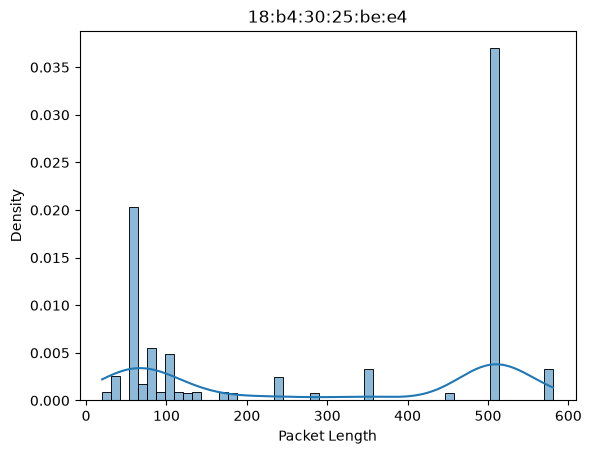

In [63]:

device = "18:b4:30:25:be:e4"

packets = all_raw_data.loc[
    all_raw_data["eth.src"] == device,
    "frame.len"
]

sns.histplot(
    packets,
    bins=50,
    stat="density",
    kde=True
)

plt.xlabel("Packet Length")
plt.title(device)

<Axes: xlabel='frame.len', ylabel='Proportion'>

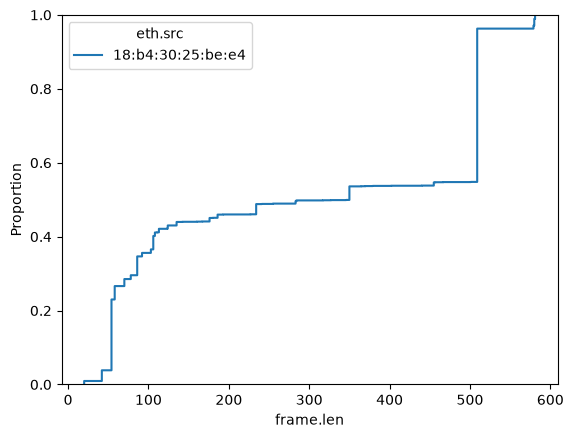

In [64]:
sns.ecdfplot(
    data=all_raw_data.loc[all_raw_data["eth.src"] == device],
    x="frame.len",
    hue="eth.src"
)